# Investigating the Effect of Input Distribution

Here, we investigate the effect of the input distribution of inference, specifically we want to compare the variance of using an SE kernel and a GAM kernel for varying input distribution correlation.

- Initially, we start by demonstrating the idea visually in 2D.
- Then, we choose and test a metric that can compare the relative uncertainty in predictions.
- Finally, we extend this test to higher dimensions on data that exists on lower-dimensional manifolds.

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

from jaxtyping import install_import_hook
import equinox as eqx
import paramax
with install_import_hook("gpjax", "beartype.beartype"):
    import gpjax as gpx
    from gpjax.kernels.additive import (
        OrthogonalAdditiveKernel,
        predict_first_order,
        rank_first_order,
        sobol_indices,
    )

## 2D Visual Tests

Sample data from different input distributions.

In [55]:
# Varying covariance

# Linspace and Logspace correlation array construction
#num_corr = 8
#rhos = np.linspace(0, 1, num_corr)
#rhos = 1 - np.logspace(0, -5, num = num_corr - 1, base = 2)
#rhos = np.concatenate([rhos, np.ones(1)])

# 1 - fractional powers correlation array construction
#powers = np.linspace(1, 20, num_corr-2)
#rhos = 0.5 ** (1/powers)
#rhos = np.concat([np.zeros(1), rhos, np.ones(1)])

# Manual correlation array construction
rhos = np.asarray([0, 0.5, 0.7, 0.8, 0.9, 0.99, 0.999, 0.9999, 1])
num_corr = rhos.shape[0]
sample_covs = jnp.array([[[1, rho], [rho, 1]] for rho in rhos])

# Sample from different covariances
N = 100
key_Xs, key_sample = jax.random.split(jax.random.key(42))
x_mean = jnp.array([0, 0])
Xs = []
for i, x_cov in enumerate(sample_covs):
    key_X = jax.random.fold_in(key_Xs, i)
    X = jax.random.multivariate_normal(key_X, x_mean, x_cov, N, method = "svd")
    print(X.shape)
    Xs.append(X)

x1_test = jnp.linspace(-4, 4, 100)
x2_test = jnp.linspace(-4, 4, 100)
X1_test, X2_test = jnp.meshgrid(x1_test, x2_test)
X_test = jnp.stack([X1_test, X2_test], axis = -1)

(100, 2)
(100, 2)
(100, 2)
(100, 2)
(100, 2)
(100, 2)
(100, 2)
(100, 2)
(100, 2)


Plot the samples on 1 axes to depict distribution shapes.

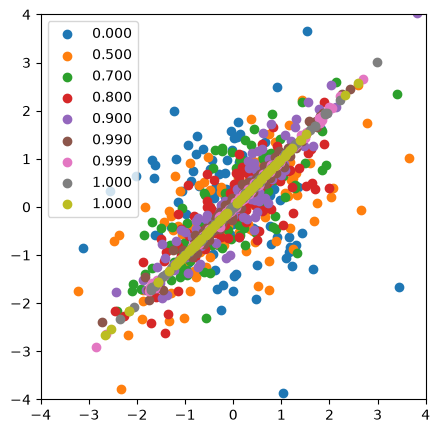

In [56]:
fig = plt.figure(figsize = (5, 5))
ax = fig.add_subplot()
for i, X in enumerate(Xs):
    ax.scatter(X[:, 0], X[:, 1], label = f"{rhos[i]:.3f}")
ax.legend()
ax.set_ylim((-4, 4))
ax.set_xlim((-4, 4))
ax.set_aspect("equal")

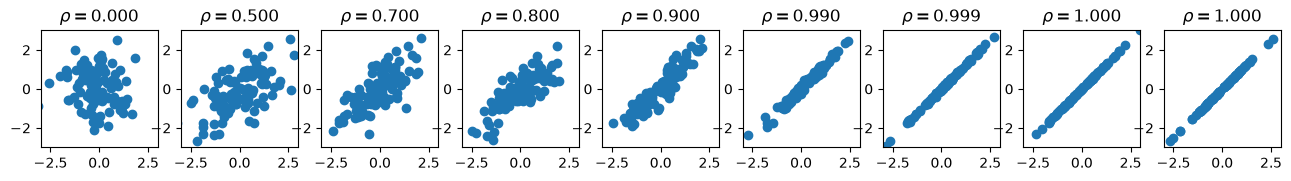

In [57]:
fig, axs = plt.subplots(1, len(Xs), figsize = (16, 4))
for i, X in enumerate(Xs):
    axs[i].scatter(X[:, 0], X[:, 1])
    axs[i].set_title(rf"$\rho = {rhos[i]:.3f}$")
    axs[i].set_ylim((-3, 3))
    axs[i].set_xlim((-3, 3))
    axs[i].set_aspect("equal")

Sample arbitrary GAM with SE base kernels.

In [58]:
# Build the kernel
base_kernels = [gpx.kernels.RBF(active_dims = [i]) for i in range(2)]
kernel_GAM = gpx.kernels.SumKernel(kernels=base_kernels)
kernel_GAM_OAK = OrthogonalAdditiveKernel(base_kernels, max_order = 1)

mean_function = gpx.mean_functions.Zero()
sample_GP = gpx.gps.Prior(mean_function = mean_function, kernel = kernel_GAM)

X_union = jnp.concatenate(Xs)
X_joint = jnp.concatenate([X_union, X_test.reshape(-1, X_test.shape[-1])])
sample_dbn = sample_GP.predict(X_joint, covariance = 'dense')
sample = sample_dbn.sample(key = key_sample)

ys_noisefree = sample[:num_corr * N]
f_true = sample[num_corr * N:].reshape(X_test.shape[:-1])

var = 0
ys_noisy = ys_noisefree + jax.random.multivariate_normal(
    key = key_sample,
    mean = jnp.zeros_like(ys_noisefree),
    cov = var * jnp.eye(ys_noisefree.shape[0]),
    method = 'svd'
)

ys = []
for i in range(num_corr):
    ys.append(ys_noisy[i * N: (i + 1) * N][:, None])

Xs_jax = jnp.array(Xs)
ys_jax = jnp.array(ys)

In [59]:
def fit(X, y, model, X_test):
    train_data = gpx.Dataset(X = X, y = y)
    opt_model, _ = gpx.fit_lbfgs(
        model = model,
        objective = lambda m, d: -gpx.objectives.conjugate_mll(m, d),
        train_data = train_data
    )
    opt_posterior = opt_model | train_data
    latent_dist = opt_posterior(
        X_test.reshape(-1, X_test.shape[-1]), covariance="diagonal"
    )
    latent_mean = latent_dist.mean
    latent_std = jnp.sqrt(latent_dist.variance)

    #predictive_dist = opt_posterior.likelihood(latent_dist)
    #predictive_mean = predictive_dist.mean
    #predictive_std = jnp.sqrt(predictive_dist.variance)

    mean_surface = latent_mean.reshape(X_test.shape[:-1])
    std_surface = latent_std.reshape(X_test.shape[:-1])
    return jnp.stack([mean_surface, std_surface]), opt_model

fit_vmap = eqx.filter_jit(
    jax.vmap(
        fit,
        in_axes = (0, 0, None, None),
        out_axes = (0)
    )
)

In [60]:
mean_function = gpx.mean_functions.Zero()
kernel_SE = gpx.kernels.RBF()
prior_SE = gpx.gps.Prior(mean_function = mean_function, kernel = kernel_SE)
prior_GAM = gpx.gps.Prior(mean_function = mean_function, kernel = kernel_GAM)
prior_GAM_OAK = gpx.gps.Prior(mean_function = mean_function, kernel = kernel_GAM_OAK)
likelihood = gpx.likelihoods.Gaussian()
model_SE = prior_SE * likelihood
model_GAM = prior_GAM * likelihood
model_GAM_OAK = prior_GAM_OAK * likelihood

results_SE, opt_models_SE = fit_vmap(Xs_jax, ys_jax, model_SE, X_test)
results_GAM, opt_models_GAM = fit_vmap(Xs_jax, ys_jax, model_GAM, X_test)
results_GAM_OAK, opt_models_GAM_OAK = fit_vmap(Xs_jax, ys_jax, model_GAM_OAK, X_test)

print(results_SE.shape)

(9, 2, 100, 100)


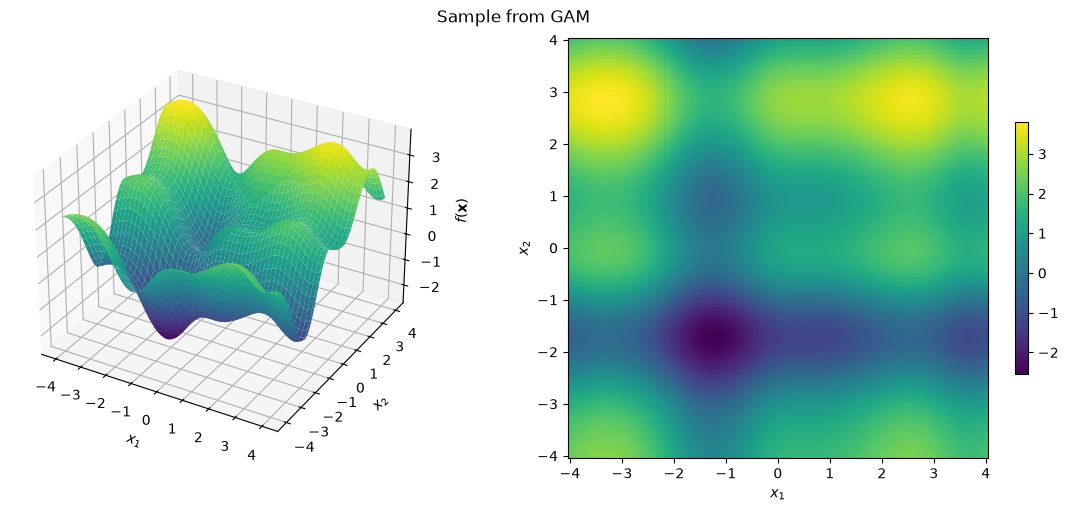

In [61]:
# True Latent Function
fig = plt.figure(figsize = (11, 5), layout = "constrained")
ax1 = fig.add_subplot(1, 2, 1, projection = "3d")
surface = ax1.plot_surface(X1_test, X2_test, f_true, cmap="viridis")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_zlabel(r"$f(\mathbf{x})$")

ax2 = fig.add_subplot(1, 2, 2)
ax2.pcolormesh(X1_test, X2_test, f_true, cmap="viridis")
ax2.set_aspect('equal')
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")

fig.suptitle("Sample from GAM")
fig.colorbar(surface, ax=ax2, shrink=0.6)

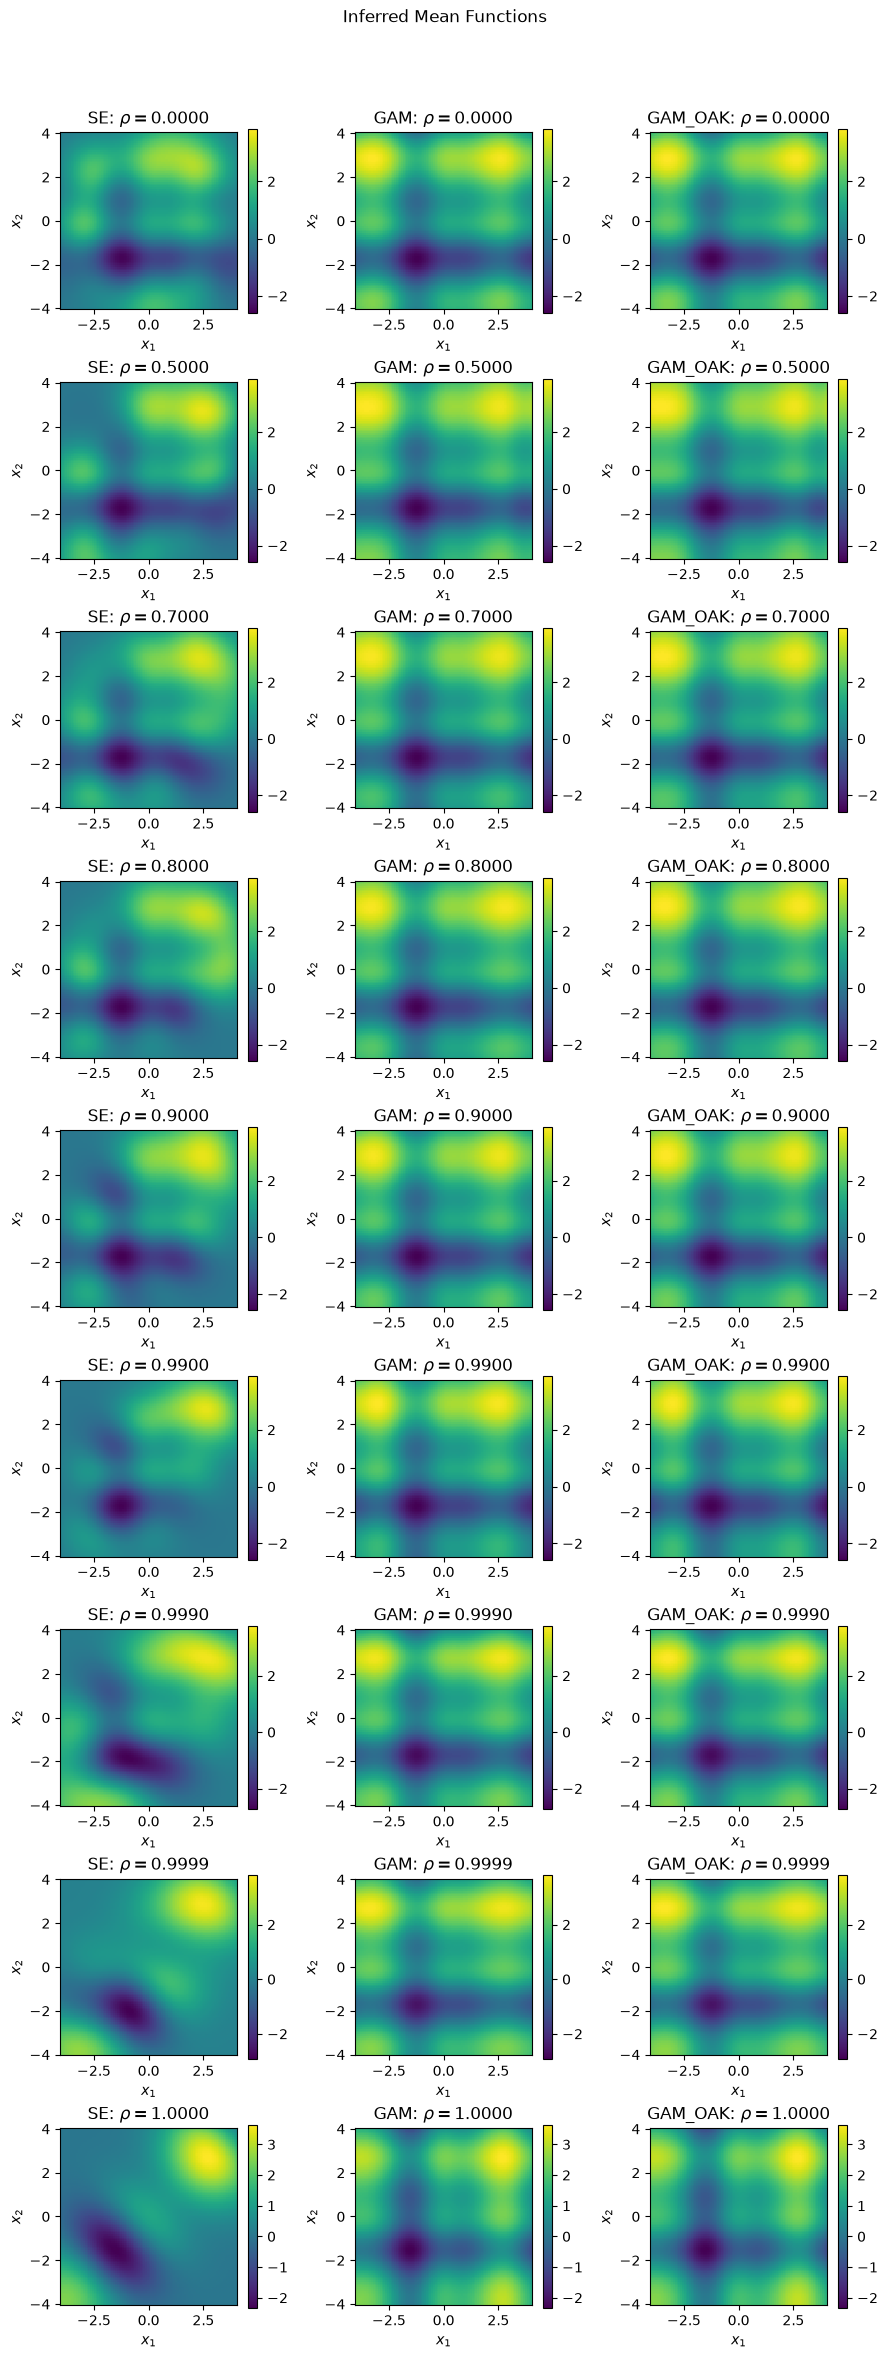

In [62]:
# Inferred Mean Plots
fig, ax = plt.subplots(num_corr, 3, figsize = (9, 3 * (num_corr - 1)))

for i in range(num_corr):
    vmin = min(results_SE[i, 0].min(), results_GAM[i, 0].min(), results_GAM_OAK[i, 0].min())
    vmax = max(results_SE[i, 0].max(), results_GAM[i, 0].max(), results_GAM_OAK[i, 0].max())
    
    im = ax[i, 0].pcolormesh(
        X1_test, X2_test, results_SE[i, 0],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 0].set_aspect("equal")
    ax[i, 0].set_xlabel(r"$x_1$")
    ax[i, 0].set_ylabel(r"$x_2$")
    ax[i, 0].set_title(rf"SE: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 0])

    im = ax[i, 1].pcolormesh(
        X1_test, X2_test, results_GAM[i, 0],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 1].set_aspect("equal")
    ax[i, 1].set_xlabel(r"$x_1$")
    ax[i, 1].set_ylabel(r"$x_2$")
    ax[i, 1].set_title(rf"GAM: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 1])    
    
    im = ax[i, 2].pcolormesh(
        X1_test, X2_test, results_GAM_OAK[i, 0],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 2].set_aspect("equal")
    ax[i, 2].set_xlabel(r"$x_1$")
    ax[i, 2].set_ylabel(r"$x_2$")
    ax[i, 2].set_title(rf"GAM_OAK: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 2])
fig.suptitle("Inferred Mean Functions")
fig.tight_layout()
fig.subplots_adjust(top=0.93)

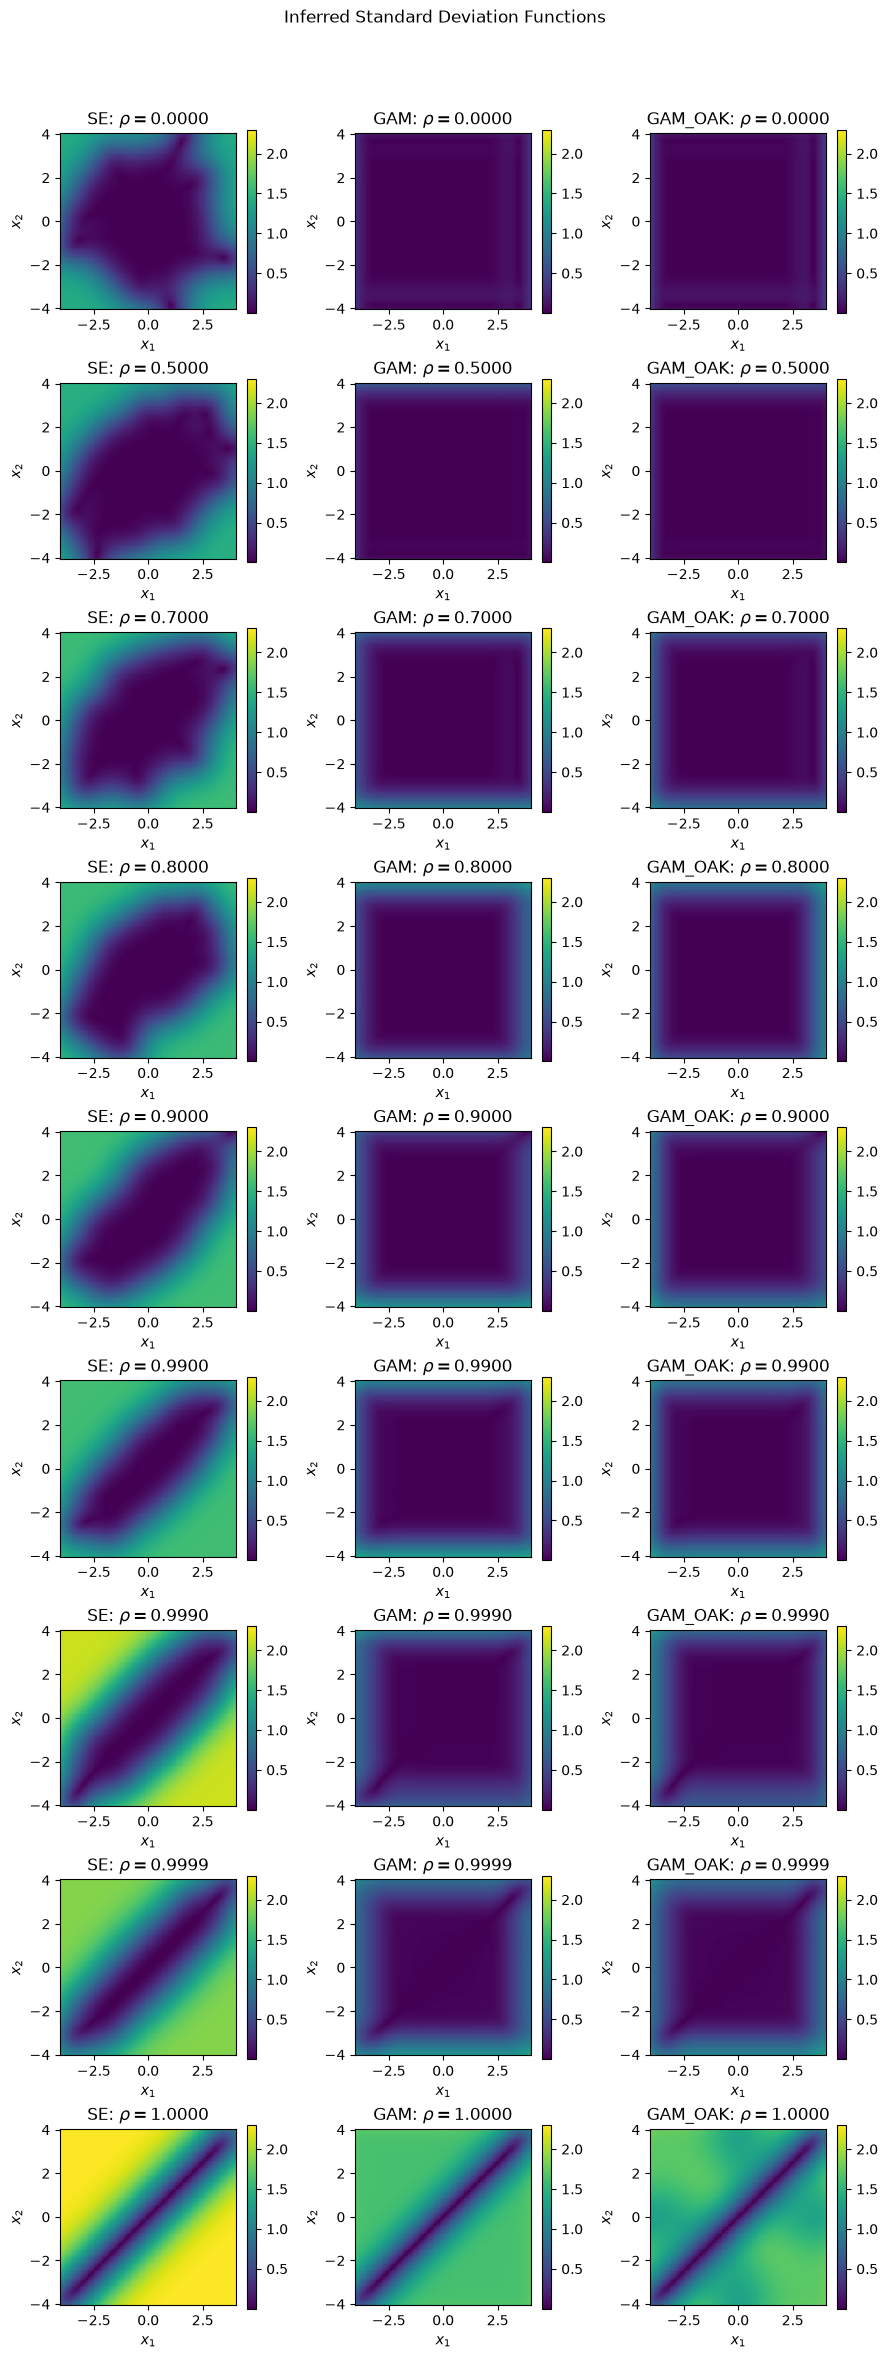

In [63]:
# Inferred Variance Plots
fig, ax = plt.subplots(num_corr, 3, figsize = (9, 3 * (num_corr - 1)))
vmin = min(results_SE[:, 1].min(), results_GAM[:, 1].min(), results_GAM_OAK[:, 1].min())
vmax = max(results_SE[:, 1].max(), results_GAM[:, 1].max(), results_GAM_OAK[:, 1].max())

for i in range(num_corr):
    
    im = ax[i, 0].pcolormesh(
        X1_test, X2_test, results_SE[i, 1],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 0].set_aspect("equal")
    ax[i, 0].set_xlabel(r"$x_1$")
    ax[i, 0].set_ylabel(r"$x_2$")
    ax[i, 0].set_title(rf"SE: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 0])

    im = ax[i, 1].pcolormesh(
        X1_test, X2_test, results_GAM[i, 1],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 1].set_aspect("equal")
    ax[i, 1].set_xlabel(r"$x_1$")
    ax[i, 1].set_ylabel(r"$x_2$")
    ax[i, 1].set_title(rf"GAM: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 1])

    im = ax[i, 2].pcolormesh(
        X1_test, X2_test, results_GAM_OAK[i, 1],
        shading="auto",
        cmap="viridis",
        vmin = vmin,
        vmax = vmax
    )
    ax[i, 2].set_aspect("equal")
    ax[i, 2].set_xlabel(r"$x_1$")
    ax[i, 2].set_ylabel(r"$x_2$")
    ax[i, 2].set_title(rf"GAM_OAK: $\rho = {rhos[i]:.4f}$")
    fig.colorbar(im, ax=ax[i, 2])
fig.suptitle("Inferred Standard Deviation Functions")
fig.tight_layout()
fig.subplots_adjust(top=0.93)

Let us plot the GP posterior along the line $x_1 = x_2$ for $\rho = 1$, since we expect the GAM and SE kernels to be equivalent up to a constant in the hyperparameters.

Text(0.5, 0.98, 'Plots of Mean Functions and 95% Confidence Intervals along $x_1 = x_2$ for $\\rho = 1$')

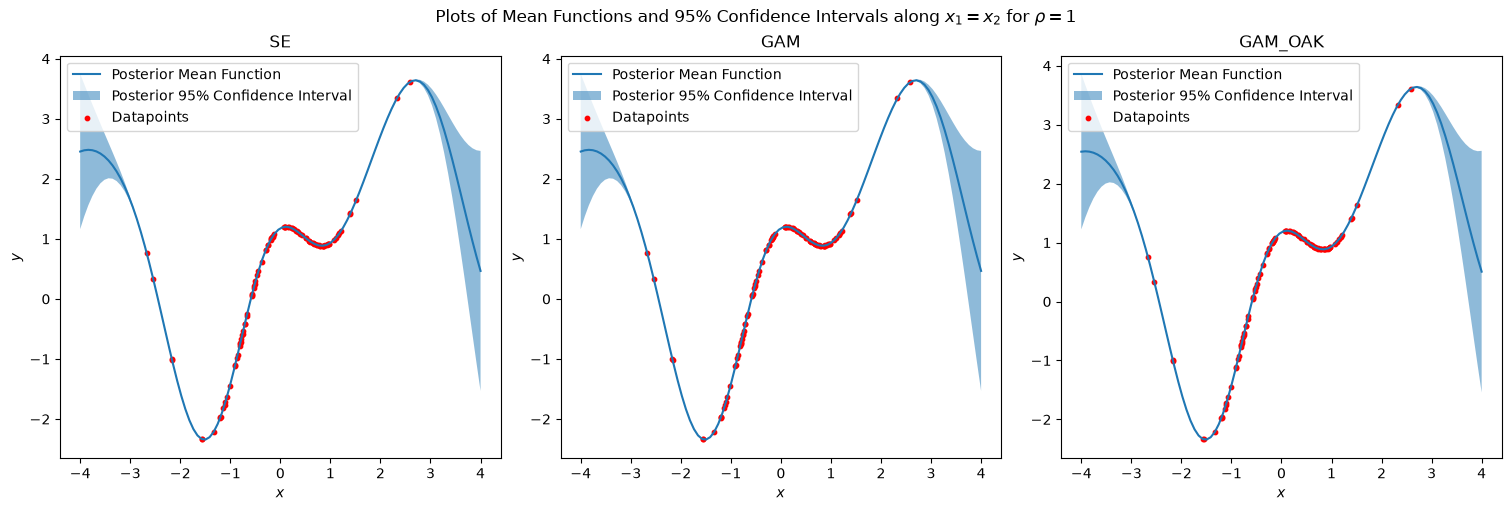

In [64]:
fig, ax = plt.subplots(1, 3, figsize = (15, 5), layout = "constrained")

diag_mean_SE = np.asarray(jnp.linalg.diagonal(results_SE[-1, 0]))
diag_std_SE = np.asarray(jnp.linalg.diagonal(results_SE[-1, 1]))
ax[0].plot(x1_test, diag_mean_SE, label = "Posterior Mean Function")
ax[0].fill_between(x1_test, diag_mean_SE - 2 * diag_std_SE, diag_mean_SE + 2 * diag_std_SE, label = "Posterior 95% Confidence Interval", alpha = 0.5)
ax[0].scatter(Xs[-1][:, 0], ys[-1][:, 0], color = 'red', s = 10, label = "Datapoints")
ax[0].set_xlabel(r"$x$")
ax[0].set_ylabel(r"$y$")
ax[0].legend()
ax[0].set_title("SE")

diag_mean_GAM = np.asarray(jnp.linalg.diagonal(results_GAM[-1, 0]))
diag_std_GAM = np.asarray(jnp.linalg.diagonal(results_GAM[-1, 1]))
ax[1].plot(x1_test, diag_mean_GAM, label = "Posterior Mean Function")
ax[1].fill_between(x1_test, diag_mean_GAM - 2 * diag_std_GAM, diag_mean_GAM + 2 * diag_std_GAM, label = "Posterior 95% Confidence Interval", alpha = 0.5)
ax[1].scatter(Xs[-1][:, 0], ys[-1][:, 0], color = 'red', s = 10, label = "Datapoints")
ax[1].set_xlabel(r"$x$")
ax[1].set_ylabel(r"$y$")
ax[1].legend()
ax[1].set_title("GAM")

diag_mean_GAM_OAK = np.asarray(jnp.linalg.diagonal(results_GAM_OAK[-1, 0]))
diag_std_GAM_OAK = np.asarray(jnp.linalg.diagonal(results_GAM_OAK[-1, 1]))
ax[2].plot(x1_test, diag_mean_GAM_OAK, label = "Posterior Mean Function")
ax[2].fill_between(x1_test, diag_mean_GAM_OAK - 2 * diag_std_GAM_OAK, diag_mean_GAM_OAK + 2 * diag_std_GAM_OAK, label = "Posterior 95% Confidence Interval", alpha = 0.5)
ax[2].scatter(Xs[-1][:, 0], ys[-1][:, 0], color = 'red', s = 10, label = "Datapoints")
ax[2].set_xlabel(r"$x$")
ax[2].set_ylabel(r"$y$")
ax[2].legend()
ax[2].set_title("GAM_OAK")

fig.suptitle(r"Plots of Mean Functions and 95% Confidence Intervals along $x_1 = x_2$ for $\rho = 1$")

Text(0.5, 1.0, 'Plots of Mean Functions and 95% Confidence Intervals along $x_1 = x_2$ for $\\rho = 1$')

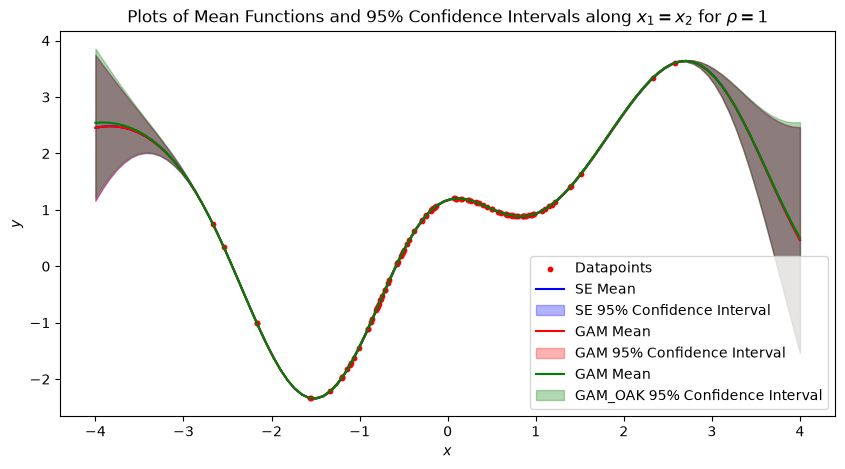

In [65]:
fig, ax = plt.subplots(1, 1, figsize = (10, 5))
ax.scatter(Xs[-1][:, 0], ys[-1][:, 0], color = 'red', s = 10, label = "Datapoints")

diag_mean_SE = np.asarray(jnp.linalg.diagonal(results_SE[-1, 0]))
diag_std_SE = np.asarray(jnp.linalg.diagonal(results_SE[-1, 1]))
ax.plot(x1_test, diag_mean_SE, 'b-', label = "SE Mean")
ax.fill_between(x1_test, diag_mean_SE - 2 * diag_std_SE, diag_mean_SE + 2 * diag_std_SE, color = "blue", label = "SE 95% Confidence Interval", alpha = 0.3)

diag_mean_GAM = np.asarray(jnp.linalg.diagonal(results_GAM[-1, 0]))
diag_std_GAM = np.asarray(jnp.linalg.diagonal(results_GAM[-1, 1]))
ax.plot(x1_test, diag_mean_GAM, 'r-', label = "GAM Mean")
ax.fill_between(x1_test, diag_mean_GAM - 2 * diag_std_GAM, diag_mean_GAM + 2 * diag_std_GAM, color = "red", label = "GAM 95% Confidence Interval", alpha = 0.3)

diag_mean_GAM_OAK = np.asarray(jnp.linalg.diagonal(results_GAM_OAK[-1, 0]))
diag_std_GAM_OAK = np.asarray(jnp.linalg.diagonal(results_GAM_OAK[-1, 1]))
ax.plot(x1_test, diag_mean_GAM_OAK, 'g-', label = "GAM Mean")
ax.fill_between(x1_test, diag_mean_GAM_OAK - 2 * diag_std_GAM_OAK, diag_mean_GAM_OAK + 2 * diag_std_GAM_OAK, color = "green", label = "GAM_OAK 95% Confidence Interval", alpha = 0.3)

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.legend()
ax.set_title(r"Plots of Mean Functions and 95% Confidence Intervals along $x_1 = x_2$ for $\rho = 1$")

We use an integrated variance metric, defined

$$
U(m, k, \mu) = \int_\mathcal{X} \mathrm{Var}\left[ f(x) \mid \mathcal{D} \right] \mathrm{d}\mu(x)
$$

with GP prior $f(x) \sim \mathcal{GP}(m, k)$, data $\mathcal{D}$ and measure of interest $\mu$. We evaluate these metrics at differing $\rho$ over the Lebesgue measure (defined on $[-4, 4]^2$), and on the input Gaussian measure.

In [66]:
# Lebesgue
UL_SE = jnp.mean(results_SE[:, 1] ** 2, axis=(1, 2))
UL_GAM = jnp.mean(results_GAM[:, 1] ** 2, axis=(1, 2))
UL_GAM_OAK = jnp.mean(results_GAM_OAK[:, 1] ** 2, axis=(1, 2))

Text(0.5, 1.0, 'Integrated variance metric over (normalised) Lebesgue measure')

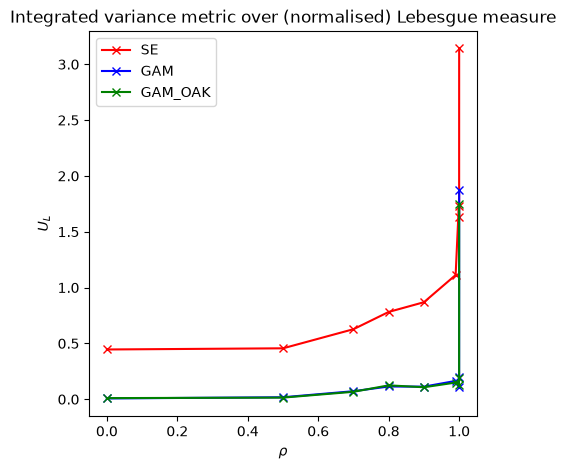

In [67]:
fig = plt.figure(figsize = (5, 5))
ax = fig.add_subplot()
ax.plot(rhos, UL_SE, "r-x", label = "SE")
ax.plot(rhos, UL_GAM, "b-x", label = "GAM")
ax.plot(rhos, UL_GAM_OAK, "g-x", label = "GAM_OAK")
ax.legend()
ax.set_ylabel(r"$U_L$")
ax.set_xlabel(r"$\rho$")
ax.set_title("Integrated variance metric over (normalised) Lebesgue measure")

In [68]:
# Gaussian
# Generate independent samples to use for MC integral estimation
z_eval = jax.random.normal(
    jax.random.key(51),
    shape=(10000, 2),
    dtype=jnp.float64,
)

def IVAR_Gaussian(model, X, y, rho, z):
    data = gpx.Dataset(X, y)
    posterior = model | data

    X_eval = jnp.stack(
        [
            z[:, 0],
            rho * z[:, 0] + jnp.sqrt(1.0 - rho**2) * z[:, 1],
        ],
        axis=-1,
    )
    latent = posterior(X_eval, covariance="diagonal")
    variances = latent.variance.reshape(-1)
    ivar = jnp.mean(variances)
    mc_error = jnp.std(variances, ddof=1) / jnp.sqrt(variances.size)
    return ivar, mc_error

IVAR_Gaussian_vmap = jax.jit(jax.vmap(IVAR_Gaussian, in_axes = (0, 0, 0, 0, None), out_axes = (0)))

UG_SE, _ = IVAR_Gaussian_vmap(opt_models_SE, Xs_jax, ys_jax, rhos, z_eval)
UG_GAM, _ = IVAR_Gaussian_vmap(opt_models_GAM, Xs_jax, ys_jax, rhos, z_eval)
UG_GAM_OAK, _ = IVAR_Gaussian_vmap(opt_models_GAM_OAK, Xs_jax, ys_jax, rhos, z_eval)

Text(0.5, 1.0, 'Integrated variance metric over respective input measure')

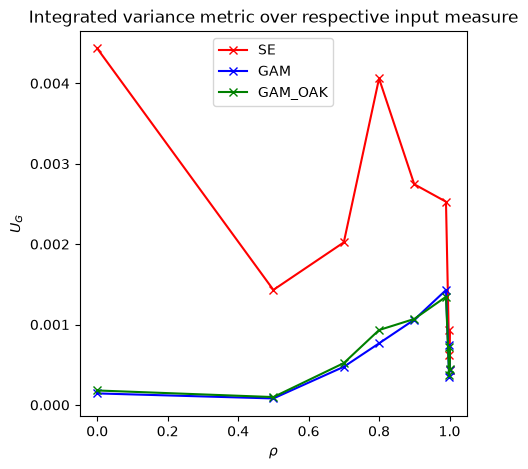

In [69]:
fig = plt.figure(figsize = (5, 5))
ax = fig.add_subplot()
ax.plot(rhos, UG_SE, "r-x", label = "SE")
ax.plot(rhos, UG_GAM, "b-x", label = "GAM")
ax.plot(rhos, UG_GAM_OAK, "g-x", label = "GAM_OAK")
ax.legend()
ax.set_ylabel(r"$U_G$")
ax.set_xlabel(r"$\rho$")
ax.set_title("Integrated variance metric over respective input measure")